# Agro Risk Intelligence — Análise de Risco Operacional com Python
**Sprint 4 · Refinamento, validação e relatório final**

| Integrante | RM |
|---|---|
| Felipe Piccolo Terra Cabral | 569324 |
| Leonardo Bueno | 572152 |
| João Vitor Andrade Veiga dos Santos | 569874 |
| Danilo Keithi | 574137 |

**Como ler este notebook:** ele segue a ordem *problema → dados → modelo → testes → cenários → relatório → conclusões*. Execute com **Kernel > Restart & Run All**; nenhuma célula pede entrada do usuário e todos os resultados são reproduzíveis (semente fixa).

## 1. Problema e solução

Máquinas agrícolas (tratores, colheitadeiras) ficam em campo aberto, muitas vezes desligadas e sem vigilância. Os dois sinistros mais relevantes levantados com o produtor rural e com um ex-gestor de sinistros agrícolas foram **furto/roubo** e **incêndio**.

**Solução:** um dispositivo IoT (ESP32) em cada máquina mede vibração, abertura do capô e do tanque, RFID do operador, GPS, temperatura do escape, chama e umidade do ar. Esses sinais viram **eventos** (ex.: `furto_capo`, `chama_detectada`) e **medidas resumidas** (temperatura máxima do escape, umidade mínima). O código Python deste notebook transforma isso em um **score de risco de 0 a 100 por eixo (furto e incêndio)** e em uma classificação **BAIXO / MÉDIO / ALTO**, que a seguradora usa para priorizar vistorias e precificar.

**O que a Sprint 4 acrescenta ao que já existia (Sprint 3):**

| Etapa | Antes (modelo v1, em produção no painel) | Agora (modelo v2, neste notebook) |
|---|---|---|
| Score | soma simples dos pontos de severidade, limitada a 100 | pontos com retorno decrescente + contexto (horário, temperatura, umidade) + padrão coordenado |
| Dados | assumidos corretos | limpeza e validação antes do cálculo |
| Faixas | 34 / 67 fixas | calibradas em dados de treino e avaliadas em dados de teste |
| Saída | números | alertas em texto claro, com fatores e ação recomendada |
| Testes | testes unitários isolados | bateria de casos extremos com resultado esperado |

## 2. Dicionário de variáveis

**Eventos** (um registro por ocorrência detectada pelo dispositivo):

| Variável | Tipo | Descrição |
|---|---|---|
| `maquina` | texto | identificação da máquina (ex.: `TR-007`) |
| `fazenda` | texto | fazenda a que a máquina pertence |
| `tipo` | texto | tipo do evento (tabela abaixo) |
| `severidade` | inteiro 0–5 | gravidade atribuída pelo firmware; vazia = usa o padrão do tipo |
| `hora` | inteiro 0–23 | hora do dia em que ocorreu |

**Medidas resumidas por máquina no período:**

| Variável | Unidade | Faixa válida | Origem |
|---|---|---|---|
| `temp_escape_max` | °C | 0 a 1023,75 | termopar tipo K + MAX6675 |
| `umidade_min` | % UR | 0 a 100 | AHT10 |

**Tipos de evento, eixo e severidade padrão:**

| Tipo | Eixo | Severidade padrão | Significado |
|---|---|---|---|
| `furto_adulteracao` | furto | 4 | vibração com a máquina desligada |
| `furto_cerca` | furto | 4 | saída do perímetro (GPS) |
| `furto_capo` | furto | 2 | capô aberto |
| `furto_tanque` | furto | 3 | tampa do tanque aberta |
| `operador_nao_autorizado` | furto | 3 | cartão RFID não cadastrado |
| `sensor_falha` | furto | 3 | sensor de adulteração desconectado |
| `escape_atencao` | incêndio | 2 | escape acima do limiar de atenção |
| `escape_critico` | incêndio | 4 | escape acima do limiar crítico |
| `chama_detectada` | incêndio | 5 | sensor de chama acionado |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

# Tabelas do domínio (as mesmas regras do módulo de scores do painel)
EIXO = {
    "furto_adulteracao": "furto", "furto_cerca": "furto", "furto_capo": "furto",
    "furto_tanque": "furto", "operador_nao_autorizado": "furto", "sensor_falha": "furto",
    "escape_atencao": "incendio", "escape_critico": "incendio", "chama_detectada": "incendio",
}
SEVERIDADE_PADRAO = {
    "furto_adulteracao": 4, "furto_cerca": 4, "furto_capo": 2, "furto_tanque": 3,
    "operador_nao_autorizado": 3, "sensor_falha": 3,
    "escape_atencao": 2, "escape_critico": 4, "chama_detectada": 5,
}
PONTOS_POR_SEVERIDADE = {0: 0, 1: 5, 2: 10, 3: 20, 4: 40, 5: 70}
NIVEIS = ["BAIXO", "MEDIO", "ALTO"]
print("Eixos:", sorted(set(EIXO.values())), "| tipos de evento:", len(EIXO))

Eixos: ['furto', 'incendio'] | tipos de evento: 9


## 3. Dados

Ainda não há uma frota real em operação (só a unidade de demonstração do NEXT), então os dados são **simulados com regras que imitam o campo**: 120 máquinas em 3 fazendas, 30 dias de operação. Cada máquina recebe um **perfil de risco real escondido** (baixo, médio ou alto, e em qual eixo), que controla a frequência dos eventos. Esse perfil é o nosso "gabarito", usado só para medir se o modelo acerta.

**Premissa explícita:** cerca de 35% das máquinas de baixo risco estão em **manutenção ou abastecimento intenso**, com rajadas de aberturas de capô e de tanque durante o dia. Isso é comum no campo e é justamente o tipo de ruído que enganava o v1; sem essa premissa, o gerador não teria nada que o v2 tratasse melhor que o v1, e o resultado da seção 4.3 depende dela (veja as limitações na seção 10).

Para testar a qualidade dos dados, o gerador também **injeta defeitos** parecidos com os que o firmware e o banco podem produzir: eventos duplicados, tipos digitados com caixa diferente, severidade vazia e leituras impossíveis de sensor.

In [2]:
FAZENDAS = ["Santa Rita", "Vale Verde", "Boa Esperanca"]
# Eventos esperados por eixo em 30 dias, conforme o nível de risco real do eixo
TOTAL_MES = {"baixo": 1.2, "medio": 5.0, "alto": 14.0}
# Composição dos eventos de cada eixo por nível: os graves (cerca, adulteração, chama) só pesam nos níveis altos
PESOS = {
    "furto": {
        "baixo": {"furto_capo": 0.55, "furto_tanque": 0.25, "operador_nao_autorizado": 0.15, "furto_adulteracao": 0.05},
        "medio": {"furto_capo": 0.40, "furto_tanque": 0.25, "operador_nao_autorizado": 0.20, "furto_adulteracao": 0.10, "furto_cerca": 0.03, "sensor_falha": 0.02},
        "alto":  {"furto_capo": 0.30, "furto_tanque": 0.20, "operador_nao_autorizado": 0.20, "furto_adulteracao": 0.20, "furto_cerca": 0.08, "sensor_falha": 0.02},
    },
    "incendio": {
        "baixo": {"escape_atencao": 0.85, "escape_critico": 0.15},
        "medio": {"escape_atencao": 0.70, "escape_critico": 0.28, "chama_detectada": 0.02},
        "alto":  {"escape_atencao": 0.50, "escape_critico": 0.30, "chama_detectada": 0.20},
    },
}

def gerar_frota(n_maquinas=120):
    linhas = []
    for i in range(1, n_maquinas + 1):
        perfil = rng.choice(["baixo", "medio", "alto"], p=[0.5, 0.3, 0.2])
        eixo_afetado = "nenhum" if perfil == "baixo" else rng.choice(["furto", "incendio", "ambos"], p=[0.4, 0.4, 0.2])
        # Parte das máquinas de baixo risco está em manutenção/abastecimento intenso:
        # muita abertura de capô e de tanque, de dia, sem relação com furto.
        manutencao = perfil == "baixo" and rng.random() < 0.35
        linhas.append({"maquina": f"TR-{i:03d}", "fazenda": FAZENDAS[(i - 1) % 3],
                       "perfil_real": perfil, "eixo_afetado": eixo_afetado, "manutencao_intensa": manutencao})
    return pd.DataFrame(linhas)

def gerar_eventos(frota):
    registros = []
    for _, m in frota.iterrows():
        for eixo in ("furto", "incendio"):
            afetado = m.eixo_afetado == "ambos" or m.eixo_afetado == eixo
            nivel = m.perfil_real if afetado else "baixo"
            n = rng.poisson(TOTAL_MES[nivel])
            tipos = list(PESOS[eixo][nivel]); probs = np.array(list(PESOS[eixo][nivel].values()))
            for tipo in rng.choice(tipos, size=n, p=probs / probs.sum()):
                # furto de verdade acontece mais à noite; no resto o horário é uniforme
                noturno = eixo == "furto" and nivel != "baixo" and rng.random() < 0.65
                hora = int(rng.choice([22, 23, 0, 1, 2, 3, 4, 5])) if noturno else int(rng.integers(6, 22))
                sev = SEVERIDADE_PADRAO[tipo] + int(rng.choice([-1, 0, 0, 0, 1]))
                registros.append({"maquina": m.maquina, "fazenda": m.fazenda, "tipo": str(tipo),
                                  "severidade": int(np.clip(sev, 0, 5)), "hora": hora})
        if m.manutencao_intensa:                      # rajada de eventos banais, só de dia
            for tipo, media in (("furto_capo", 6), ("furto_tanque", 2)):
                for _ in range(rng.poisson(media)):
                    registros.append({"maquina": m.maquina, "fazenda": m.fazenda, "tipo": tipo,
                                      "severidade": SEVERIDADE_PADRAO[tipo], "hora": int(rng.integers(7, 17))})
    return pd.DataFrame(registros)

def gerar_medidas(frota):
    linhas = []
    for _, m in frota.iterrows():
        inc = m.eixo_afetado in ("incendio", "ambos")
        nivel = m.perfil_real if inc else "baixo"
        temp = {"baixo": (28, 5), "medio": (44, 6), "alto": (60, 8)}[nivel]
        umid = {"baixo": (45, 8), "medio": (32, 8), "alto": (20, 6)}[nivel]
        linhas.append({"maquina": m.maquina,
                       "temp_escape_max": float(np.clip(rng.normal(*temp), 15, 120)),
                       "umidade_min": float(np.clip(rng.normal(*umid), 5, 90))})
    return pd.DataFrame(linhas)

frota = gerar_frota()
eventos_limpos_origem = gerar_eventos(frota)
medidas_origem = gerar_medidas(frota)
print(frota.perfil_real.value_counts().to_dict(), "| eventos gerados:", len(eventos_limpos_origem))

{np.str_('baixo'): 67, np.str_('medio'): 36, np.str_('alto'): 17} | eventos gerados: 961


In [3]:
def sujar_dados(eventos, medidas):
    # Injeta defeitos realistas para a etapa de limpeza ter o que corrigir.
    ev = eventos.copy()
    md_ = medidas.copy()
    dup = ev.sample(frac=0.03, random_state=SEMENTE)                    # reenvio do mesmo evento
    ev = pd.concat([ev, dup], ignore_index=True)
    idx = ev.sample(frac=0.04, random_state=1).index
    ev.loc[idx, "tipo"] = ev.loc[idx, "tipo"].str.upper()               # caixa diferente
    idx = ev.sample(frac=0.05, random_state=2).index
    ev.loc[idx, "severidade"] = np.nan                                  # severidade vazia
    idx = ev.sample(n=4, random_state=3).index
    ev.loc[idx, "tipo"] = "evento_desconhecido"                         # tipo que o modelo não conhece
    idx = ev.sample(n=3, random_state=4).index
    ev.loc[idx, "hora"] = 27                                            # hora impossível
    md_.loc[md_.sample(n=2, random_state=5).index, "temp_escape_max"] = -999.0   # leitura de erro do sensor
    md_.loc[md_.sample(n=2, random_state=6).index, "umidade_min"] = 140.0        # umidade > 100 %
    md_.loc[md_.sample(n=2, random_state=7).index, "temp_escape_max"] = np.nan   # sensor sem leitura
    return ev, md_

eventos_brutos, medidas_brutas = sujar_dados(eventos_limpos_origem, medidas_origem)
print("Eventos brutos:", len(eventos_brutos), "| medidas:", len(medidas_brutas))
eventos_brutos.head(8)

Eventos brutos: 990 | medidas: 120


,maquina,fazenda,tipo,severidade,hora
0,TR-001,Santa Rita,furto_capo,3.0,20
1,TR-001,Santa Rita,furto_tanque,3.0,18
2,TR-001,Santa Rita,escape_atencao,1.0,11
3,TR-001,Santa Rita,escape_critico,5.0,9
4,TR-001,Santa Rita,escape_critico,4.0,11
5,TR-001,Santa Rita,escape_atencao,1.0,20
6,TR-001,Santa Rita,ESCAPE_ATENCAO,3.0,20
7,TR-001,Santa Rita,escape_atencao,1.0,15


### 3.1 Qualidade dos dados: limpeza e validação

Regra de ouro herdada do firmware: **leitura inválida nunca vira dado**. Aqui ela é descartada (ou marcada como *sem leitura*), nunca "consertada" com um número inventado. Cada correção é contada, e o relatório final mostra quanto do dado foi afetado.

In [4]:
TEMP_MIN, TEMP_MAX = 0.0, 1023.75     # faixa física do MAX6675
UMID_MIN, UMID_MAX = 0.0, 100.0       # faixa do AHT10

def limpar_eventos(df):
    """Devolve (eventos limpos, relatório de correções)."""
    rel = {"recebidos": len(df)}
    d = df.copy()
    d["tipo"] = d["tipo"].str.strip().str.lower()                      # padroniza caixa/espaços
    rel["duplicados_removidos"] = int(d.duplicated().sum())
    d = d.drop_duplicates()
    desconhecido = ~d["tipo"].isin(EIXO)
    rel["tipo_desconhecido_removidos"] = int(desconhecido.sum())
    d = d[~desconhecido]
    hora_ruim = ~d["hora"].between(0, 23)
    rel["hora_invalida_removidos"] = int(hora_ruim.sum())
    d = d[~hora_ruim]
    vazia = d["severidade"].isna()
    rel["severidade_vazia_preenchida_com_padrao"] = int(vazia.sum())
    d.loc[vazia, "severidade"] = d.loc[vazia, "tipo"].map(SEVERIDADE_PADRAO)
    d["severidade"] = d["severidade"].astype(int).clip(0, 5)
    d["eixo"] = d["tipo"].map(EIXO)
    rel["finais"] = len(d)
    return d.reset_index(drop=True), rel

def limpar_medidas(df):
    d = df.copy()
    rel = {}
    ruim_t = ~d["temp_escape_max"].between(TEMP_MIN, TEMP_MAX)         # NaN também cai aqui
    ruim_u = ~d["umidade_min"].between(UMID_MIN, UMID_MAX)
    rel["temperatura_invalida_marcada_sem_leitura"] = int(ruim_t.sum())
    rel["umidade_invalida_marcada_sem_leitura"] = int(ruim_u.sum())
    d.loc[ruim_t, "temp_escape_max"] = np.nan
    d.loc[ruim_u, "umidade_min"] = np.nan
    return d, rel

eventos, rel_ev = limpar_eventos(eventos_brutos)
medidas, rel_med = limpar_medidas(medidas_brutas)
pd.Series({**rel_ev, **rel_med}, name="quantidade").to_frame()

,quantidade
recebidos,990
duplicados_removidos,87
tipo_desconhecido_removidos,4
hora_invalida_removidos,3
severidade_vazia_preenchida_com_padrao,49
finais,896
temperatura_invalida_marcada_sem_leitura,4
umidade_invalida_marcada_sem_leitura,2


## 4. Modelo de risco

### 4.1 Modelo v1 (baseline: o que estava no painel)

Cada evento vale pontos conforme a severidade (0→0, 1→5, 2→10, 3→20, 4→40, 5→70). O score do eixo é a **soma**, limitada a 100. Faixas: BAIXO < 34, MÉDIO 34–66, ALTO ≥ 67.

In [5]:
def classificar(score, t_medio=34, t_alto=67):
    return "ALTO" if score >= t_alto else ("MEDIO" if score >= t_medio else "BAIXO")

def score_v1(eventos):
    """Baseline: soma de pontos por severidade, teto 100. 'eventos' = lista de dicts."""
    soma = {"furto": 0, "incendio": 0}
    for e in eventos:
        eixo = EIXO.get(e.get("tipo"))
        if eixo is None:
            continue
        sev = e.get("severidade")
        sev = SEVERIDADE_PADRAO[e["tipo"]] if sev is None or sev != sev else int(sev)
        soma[eixo] += PONTOS_POR_SEVERIDADE[max(0, min(5, sev))]
    return {eixo: min(100, v) for eixo, v in soma.items()}

# Fraqueza do v1: eventos banais repetidos "estouram" o score
abre_capo = [{"tipo": "furto_capo", "severidade": 2, "hora": 11}] * 12
um_critico = [{"tipo": "furto_adulteracao", "severidade": 4, "hora": 14}, {"tipo": "furto_cerca", "severidade": 4, "hora": 14}]
print("12 aberturas de capô (rotina de manutenção):", score_v1(abre_capo)["furto"], "->", classificar(score_v1(abre_capo)["furto"]))
print("1 adulteração + 1 saída de cerca (indício real):", score_v1(um_critico)["furto"], "->", classificar(score_v1(um_critico)["furto"]))

12 aberturas de capô (rotina de manutenção): 100 -> ALTO
1 adulteração + 1 saída de cerca (indício real): 80 -> ALTO


**Diagnóstico do v1.** Três problemas apareceram nos testes:

1. **Saturação por volume.** Doze aberturas de capô (rotina de manutenção) dão 100 e "ALTO", enquanto dois indícios graves de furto dão 80. O volume de eventos banais engana mais que a gravidade.
2. **Ignora o contexto.** O mesmo `furto_capo` às 3 da manhã e às 14h valem igual. Temperatura do escape e umidade do ar, que o dispositivo mede o tempo todo, não entram no score de incêndio.
3. **Não separa evento isolado de padrão coordenado.** Capô + tanque + operador não autorizado na mesma janela é o roteiro típico de furto de combustível/peças, e vale mais que a soma das partes.

### 4.2 Modelo v2 (refinado)

| Ajuste | Regra | Parâmetro |
|---|---|---|
| Retorno decrescente | dentro de cada tipo, o 1º evento vale 100% dos pontos, o 2º vale `r`, o 3º `r²`... | `decaimento` (`r`) |
| Saturação suave | os pontos somados (`bruto`) viram score por `100 × (1 − e^(−bruto/K))`: cresce rápido no começo e achata perto de 100, sem "estourar" o teto | `K` |
| Horário (furto) | evento de furto entre 22h e 5h vale × `1,5`; abrir capô ou tanque durante o dia vale × `0,5` (rotina de operação e abastecimento) | `PESO_NOITE`, `PESO_ROTINA_DIA` |
| Temperatura do escape (incêndio) | até `+20` pontos, linear entre 40 °C (atenção) e 60 °C (crítico) | `TEMP_ATENCAO`, `TEMP_CRITICO` |
| Umidade do ar (incêndio) | até `+10` pontos, linear entre 40 % e 15 % UR (ar mais seco, mais risco) | `UMID_SECA`, `UMID_MUITO_SECA` |
| Padrão coordenado | `+8` pontos quando há 3 ou mais tipos distintos de evento no mesmo eixo | `BONUS_PADRAO` |
| Sem leitura | medida ausente soma 0 e fica **registrada** como "sem leitura", sem mascarar a ausência | |

`r` e `K` são escolhidos por busca em grade nas máquinas de treino (seção 4.3). Os limiares de temperatura são os do firmware da unidade de demonstração (40/60 °C); numa frota real eles seriam recalibrados para o escape de cada tipo de máquina.

In [6]:
PARAMS = {"decaimento": 0.6, "K": 50.0}     # valores iniciais; a seção 4.3 escolhe os finais com dados de treino
PESO_NOITE = 1.5          # evento de furto entre 22h e 5h
PESO_ROTINA_DIA = 0.5     # abrir capô/tanque de dia = rotina operacional
TIPOS_ROTINA = {"furto_capo", "furto_tanque"}
BONUS_PADRAO = 8
TEMP_ATENCAO, TEMP_CRITICO = 40.0, 60.0
UMID_SECA, UMID_MUITO_SECA = 40.0, 15.0
PTS_TEMP, PTS_UMID = 20, 10
NOITE = set(range(22, 24)) | set(range(0, 6))

def _linear(x, a, b):
    """0 em a, 1 em b, linear entre eles (funciona com a > b também)."""
    if x is None or x != x:
        return 0.0
    return float(np.clip((x - a) / (b - a), 0.0, 1.0))

def score_v2(eventos, temp_escape_max=None, umidade_min=None, params=None):
    """Score refinado. Devolve scores, componentes brutos (auditáveis) e avisos de dado ausente."""
    p = params or PARAMS
    comp = {"furto": {}, "incendio": {}}
    por_tipo = {}
    for e in eventos:
        tipo = e.get("tipo")
        if tipo not in EIXO:
            continue
        sev = e.get("severidade")
        sev = SEVERIDADE_PADRAO[tipo] if sev is None or sev != sev else int(sev)
        pts_evento = PONTOS_POR_SEVERIDADE[max(0, min(5, sev))]
        hora = e.get("hora")
        if EIXO[tipo] == "furto" and hora is not None and hora == hora:
            if int(hora) in NOITE:
                pts_evento *= PESO_NOITE
            elif tipo in TIPOS_ROTINA:
                pts_evento *= PESO_ROTINA_DIA
        por_tipo.setdefault(tipo, []).append(pts_evento)
    for tipo, pts in por_tipo.items():
        pts = sorted(pts, reverse=True)
        comp[EIXO[tipo]][tipo] = round(sum(x * p["decaimento"] ** k for k, x in enumerate(pts)), 1)

    saida, bruto, avisos = {}, {}, []
    for eixo in ("furto", "incendio"):
        base = sum(comp[eixo].values())
        if eixo == "incendio":
            if temp_escape_max is None or temp_escape_max != temp_escape_max:
                avisos.append("temperatura do escape sem leitura valida")
            if umidade_min is None or umidade_min != umidade_min:
                avisos.append("umidade do ar sem leitura valida")
            p_t = PTS_TEMP * _linear(temp_escape_max, TEMP_ATENCAO, TEMP_CRITICO)
            p_u = PTS_UMID * _linear(umidade_min, UMID_SECA, UMID_MUITO_SECA)
            comp[eixo]["temperatura_escape"] = round(p_t, 1)
            comp[eixo]["ar_seco"] = round(p_u, 1)
            base += p_t + p_u
        if len([t for t in por_tipo if EIXO[t] == eixo]) >= 3:
            comp[eixo]["padrao_coordenado"] = BONUS_PADRAO
            base += BONUS_PADRAO
        bruto[eixo] = round(base, 1)
        saida[eixo] = int(round(100 * (1 - np.exp(-max(0.0, base) / p["K"]))))
    return {"scores": saida, "bruto": bruto, "componentes": comp, "avisos": avisos}

print("12 aberturas de capô  v1:", score_v1(abre_capo)["furto"], "| v2:", score_v2(abre_capo)["scores"]["furto"])
print("adulteração + cerca   v1:", score_v1(um_critico)["furto"], "| v2:", score_v2(um_critico)["scores"]["furto"])

12 aberturas de capô  v1: 100 | v2: 22
adulteração + cerca   v1: 80 | v2: 80


Os dois casos que enganavam o v1 agora se ordenam como esperado: a rotina de manutenção (de dia) pontua bem menos que os indícios graves.

### 4.3 Calibração e avaliação das faixas

Para saber se o v2 de fato **acerta mais**, comparamos a classificação de cada máquina com o perfil real escondido (gabarito). O nível geral da máquina é o **pior dos dois eixos**. Para não "colar" a prova, os parâmetros do v2 são escolhidos só com **80 máquinas de treino** e a nota final vem de **40 máquinas de teste** que o ajuste nunca viu. O v1 também é avaliado com as faixas otimizadas, para mostrar quanto do ganho vem do **cálculo** e quanto vem só das **faixas**.

In [7]:
def montar_tabela_scores(eventos, medidas, frota, params=None):
    por_maq = {m: g.to_dict("records") for m, g in eventos.groupby("maquina")}
    linhas = []
    for _, m in frota.iterrows():
        ev = por_maq.get(m.maquina, [])
        med = medidas.loc[medidas.maquina == m.maquina].iloc[0]
        s1 = score_v1(ev)
        r2 = score_v2(ev, med.temp_escape_max, med.umidade_min, params)
        linhas.append({"maquina": m.maquina, "fazenda": m.fazenda, "perfil_real": m.perfil_real,
                       "n_eventos": len(ev),
                       "v1_furto": s1["furto"], "v1_incendio": s1["incendio"],
                       "v2_furto": r2["scores"]["furto"], "v2_incendio": r2["scores"]["incendio"],
                       "sem_leitura": len(r2["avisos"]) > 0})
    t = pd.DataFrame(linhas)
    t["v1_max"] = t[["v1_furto", "v1_incendio"]].max(axis=1)
    t["v2_max"] = t[["v2_furto", "v2_incendio"]].max(axis=1)
    return t

ORDEM = {"BAIXO": 0, "MEDIO": 1, "ALTO": 2}
def nivel_real(df):
    return df["perfil_real"].str.upper()

def acuracia(df, col, t_medio, t_alto):
    pred = df[col].apply(lambda s: classificar(s, t_medio, t_alto))
    return float((pred == nivel_real(df)).mean())

def erro_grave(df, col, t_medio, t_alto):
    """Fração de máquinas classificadas a 2 níveis de distância (ALTO como BAIXO ou o contrário)."""
    pred = df[col].apply(lambda s: ORDEM[classificar(s, t_medio, t_alto)])
    real = nivel_real(df).map(ORDEM)
    return float(((pred - real).abs() == 2).mean())

def melhor_faixa(df, col, tm_ate=(20, 46), ta_ate=(56, 76)):
    """Busca as faixas perto das do painel (34/67): os níveis não podem mudar de significado."""
    melhor = (-1, 34, 67)
    for tm in range(tm_ate[0], tm_ate[1] + 1, 2):
        for ta in range(max(ta_ate[0], tm + 6), ta_ate[1] + 1, 2):
            a = acuracia(df, col, tm, ta)
            if a > melhor[0]:
                melhor = (a, tm, ta)
    return melhor

# Separação treino/teste por máquina (o teste nunca participa da escolha de parâmetros)
ids = frota["maquina"].sample(frac=1.0, random_state=SEMENTE).tolist()
ids_treino, ids_teste = set(ids[:80]), set(ids[80:])

# Restrições de negócio: parâmetros que as violam são descartados ANTES de olhar a acurácia.
#   (a) uma chama detectada, sozinha, tem de ser ALTO;
#   (b) doze aberturas de capô de rotina têm de ficar em BAIXO.
chama_sozinha = [{"tipo": "chama_detectada", "severidade": 5, "hora": 14}]
rotina = [{"tipo": "furto_capo", "severidade": 2, "hora": 11}] * 12

# Busca em grade: decaimento (r) e K, com as faixas otimizadas dentro de cada candidato
candidatos = []
for r in (0.4, 0.5, 0.6, 0.7, 0.8):
    for K in (35.0, 50.0, 70.0, 100.0, 150.0):
        p = {"decaimento": r, "K": K}
        s_chama = score_v2(chama_sozinha, None, None, p)["scores"]["incendio"]
        s_rotina = score_v2(rotina, None, None, p)["scores"]["furto"]
        # As restrições limitam onde as faixas podem ficar: faixa ALTO <= score da chama; faixa MÉDIO > score da rotina.
        faixa_medio_ate = (max(20, s_rotina + 1), 46)
        faixa_alto_ate = (56, min(76, s_chama))
        if faixa_medio_ate[0] > faixa_medio_ate[1] or faixa_alto_ate[0] > faixa_alto_ate[1]:
            candidatos.append({"decaimento": r, "K": K, "faixa_medio": None, "faixa_alto": None,
                               "acuracia_treino": None, "respeita_restricoes": False})
            continue
        t = montar_tabela_scores(eventos, medidas, frota, p)
        acc, tm, ta = melhor_faixa(t[t.maquina.isin(ids_treino)], "v2_max", faixa_medio_ate, faixa_alto_ate)
        candidatos.append({"decaimento": r, "K": K, "faixa_medio": tm, "faixa_alto": ta,
                           "acuracia_treino": acc, "respeita_restricoes": True})
grade = pd.DataFrame(candidatos)
print(f"{len(grade)} combinações testadas; {int(grade.respeita_restricoes.sum())} admitem faixas que respeitam as restrições de negócio.")
grade = (grade[grade.respeita_restricoes]
         .sort_values(["acuracia_treino", "decaimento"], ascending=[False, True]).reset_index(drop=True))
print("Melhores combinações (acurácia só no treino):")
print(grade.head(5).drop(columns="respeita_restricoes").to_string(index=False, float_format=lambda x: f"{x:.2f}"))

melhor = grade.iloc[0]
PARAMS = {"decaimento": float(melhor.decaimento), "K": float(melhor.K)}
tm2, ta2 = int(melhor.faixa_medio), int(melhor.faixa_alto)

tabela = montar_tabela_scores(eventos, medidas, frota, PARAMS)
treino = tabela[tabela.maquina.isin(ids_treino)]
teste = tabela[tabela.maquina.isin(ids_teste)]
a1, tm1, ta1 = melhor_faixa(treino, "v1_max")
resultado = pd.DataFrame([
    {"modelo": "v1 (faixas 34/67 do painel)", "faixas": "34/67",
     "acuracia_treino": acuracia(treino, "v1_max", 34, 67), "acuracia_teste": acuracia(teste, "v1_max", 34, 67), "erro_grave_teste": erro_grave(teste, "v1_max", 34, 67)},
    {"modelo": "v1 com faixas otimizadas", "faixas": f"{tm1}/{ta1}",
     "acuracia_treino": a1, "acuracia_teste": acuracia(teste, "v1_max", tm1, ta1), "erro_grave_teste": erro_grave(teste, "v1_max", tm1, ta1)},
    {"modelo": f"v2 (r={PARAMS['decaimento']}, K={PARAMS['K']:g}) com faixas otimizadas", "faixas": f"{tm2}/{ta2}",
     "acuracia_treino": melhor.acuracia_treino, "acuracia_teste": acuracia(teste, "v2_max", tm2, ta2), "erro_grave_teste": erro_grave(teste, "v2_max", tm2, ta2)},
])
for c in ("acuracia_treino", "acuracia_teste", "erro_grave_teste"):
    resultado[c] = resultado[c].map("{:.0%}".format)
resultado

25 combinações testadas; 14 admitem faixas que respeitam as restrições de negócio.
Melhores combinações (acurácia só no treino):
 decaimento     K  faixa_medio  faixa_alto  acuracia_treino
       0.70 70.00        46.00       60.00             0.57
       0.40 70.00        38.00       60.00             0.56
       0.50 70.00        40.00       60.00             0.56
       0.60 70.00        46.00       60.00             0.56
       0.80 70.00        45.00       60.00             0.55


,modelo,faixas,acuracia_treino,acuracia_teste,erro_grave_teste
0,v1 (faixas 34/67 do painel),34/67,45%,40%,30%
1,v1 com faixas otimizadas,32/72,49%,40%,25%
2,"v2 (r=0.7, K=70) com faixas otimizadas",46/60,57%,70%,5%


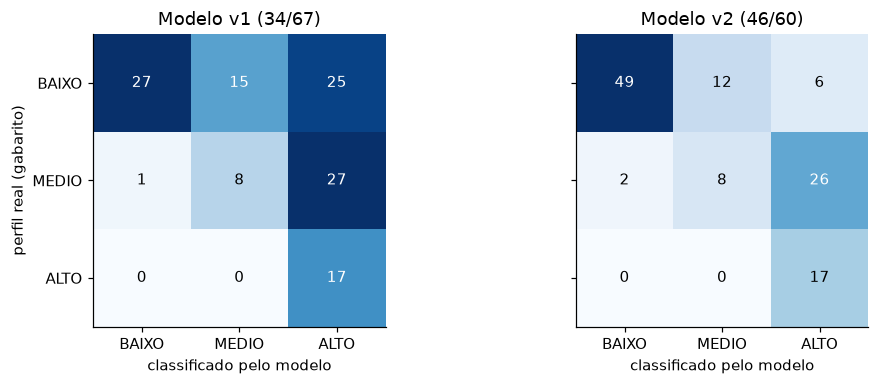

In [8]:
FAIXA_MEDIO_V2, FAIXA_ALTO_V2 = tm2, ta2
tabela["nivel_v1"] = tabela["v1_max"].apply(classificar)
tabela["nivel_v2"] = tabela["v2_max"].apply(lambda s: classificar(s, FAIXA_MEDIO_V2, FAIXA_ALTO_V2))
tabela["gabarito"] = tabela["perfil_real"].str.upper()

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, titulo in zip(eixos, ["nivel_v1", "nivel_v2"], ["Modelo v1 (34/67)", f"Modelo v2 ({FAIXA_MEDIO_V2}/{FAIXA_ALTO_V2})"]):
    ct = pd.crosstab(tabela["gabarito"], tabela[col]).reindex(index=NIVEIS, columns=NIVEIS, fill_value=0)
    ax.imshow(ct.values, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, ct.values[i, j], ha="center", va="center", color="white" if ct.values[i, j] > ct.values.max() / 2 else "black")
    ax.set_xticks(range(3), NIVEIS); ax.set_yticks(range(3), NIVEIS)
    ax.set_xlabel("classificado pelo modelo"); ax.set_title(titulo)
eixos[0].set_ylabel("perfil real (gabarito)")
plt.tight_layout(); plt.show()

**Leitura.** A diagonal é acerto. Compare a tabela de acurácia e a coluna `erro_grave_teste` (ALTO tratado como BAIXO ou o contrário): o v2 acerta mais no **teste** e comete bem menos erros graves, enquanto otimizar só as faixas do v1 quase não muda o resultado. Ou seja, o ganho vem do **cálculo** (retorno decrescente, saturação e peso do horário), não só do ajuste de faixas. Três ressalvas honestas:

1. O gabarito é simulado, então a acurácia mostra que o modelo recupera o padrão que **nós mesmos** programamos no gerador, incluindo a premissa de manutenção intensa. Em campo, o número vai ser outro.
2. Com 40 máquinas de teste, a nota oscila vários pontos percentuais com outra semente; o que importa é a comparação v1 x v2 **nas mesmas condições**.
3. O nível **MÉDIO** continua sendo o mais difícil: a matriz mostra que o v2 ainda joga a maior parte das máquinas de risco médio para ALTO. Para uma seguradora esse é o lado seguro do erro (vistoria desnecessária custa menos que sinistro não previsto), mas é o principal ponto de melhoria.

## 5. Validação e testes

Bateria de casos de entrada, incluindo extremos. Cada teste tem um **resultado esperado** escrito antes de rodar; a tabela mostra se o modelo cumpriu.

In [9]:
def ev(tipo, n=1, sev=None, hora=14):
    return [{"tipo": tipo, "severidade": sev, "hora": hora}] * n

testes = []
def verificar(nome, condicao, detalhe=""):
    testes.append({"teste": nome, "resultado": "PASSOU" if condicao else "FALHOU", "detalhe": detalhe})

# 1. Entradas vazias / ausentes
r = score_v2([])
verificar("lista de eventos vazia dá score 0 nos dois eixos", r["scores"] == {"furto": 0, "incendio": 0}, str(r["scores"]))
r = score_v2([], None, None)
verificar("sem medidas: avisa em vez de inventar valor", len(r["avisos"]) == 2, "; ".join(r["avisos"]))
r = score_v2([], float("nan"), float("nan"))
verificar("NaN nas medidas é tratado como sem leitura", len(r["avisos"]) == 2)

# 2. Dados sujos
r = score_v2([{"tipo": "inexistente", "severidade": 5, "hora": 3}])
verificar("tipo desconhecido é ignorado", r["scores"] == {"furto": 0, "incendio": 0})
r = score_v2([{"tipo": "chama_detectada", "severidade": 99, "hora": 3}])
verificar("severidade fora de 0..5 é limitada a 5", r["scores"] == score_v2([{"tipo": "chama_detectada", "severidade": 5, "hora": 3}])["scores"], f"score={r['scores']['incendio']}")
r = score_v2([{"tipo": "chama_detectada", "severidade": None, "hora": 3}])
verificar("severidade vazia usa o padrão do tipo (chama = 5)", r["scores"] == score_v2([{"tipo": "chama_detectada", "severidade": 5, "hora": 3}])["scores"])

# 3. Extremos de volume e de sensor
r = score_v2(ev("chama_detectada", 1000), 900.0, 0.0)
verificar("1000 chamas + sensores extremos: score <= 100 e acima de 1 chama só", score_v2(ev("chama_detectada", 1, 5), 25.0, 50.0)["scores"]["incendio"] < r["scores"]["incendio"] <= 100, str(r["scores"]))
r = score_v2([], -50.0, 150.0)
verificar("temperatura negativa e umidade > 100 não geram pontos negativos", r["scores"]["incendio"] == 0, str(r["scores"]))
r = score_v2([], 60.0, 15.0)
verificar("temperatura crítica + ar muito seco somam exatamente 30 pontos brutos", r["bruto"]["incendio"] == 30, f"bruto={r['bruto']['incendio']}")

# 4. Propriedades do modelo
base = [{"tipo": "furto_tanque", "severidade": 3, "hora": 10}]
mais = base + [{"tipo": "furto_capo", "severidade": 2, "hora": 10}]
verificar("monotonia: acrescentar evento nunca reduz o score", score_v2(mais)["scores"]["furto"] >= score_v2(base)["scores"]["furto"])
verificar("determinismo: mesma entrada, mesma saída", score_v2(mais) == score_v2(mais))
dia, noite = ev("furto_tanque", 1, 3, 14), ev("furto_tanque", 1, 3, 2)
verificar("o mesmo evento vale mais de madrugada que à tarde", score_v2(noite)["scores"]["furto"] > score_v2(dia)["scores"]["furto"],
      f"dia={score_v2(dia)['scores']['furto']} noite={score_v2(noite)['scores']['furto']}")
verificar("12 aberturas de capô pontuam menos que 2 indícios graves no v2", score_v2(abre_capo)["scores"]["furto"] < score_v2(um_critico)["scores"]["furto"])
todos = [ev(t, n, None, h) for t in EIXO for n in (0, 1, 7) for h in (3, 14)]
verificar("score sempre entre 0 e 100 (54 combinações)", all(0 <= s <= 100 for lst in todos for s in score_v2(lst, 55.0, 20.0)["scores"].values()))
verificar("classificar() respeita as bordas das faixas", (classificar(33), classificar(34), classificar(66), classificar(67)) == ("BAIXO", "MEDIO", "MEDIO", "ALTO"))

# 5. Pipeline completo
verificar("a limpeza deixa todos os eventos com tipo e hora válidos", eventos["tipo"].isin(EIXO).all() and eventos["hora"].between(0, 23).all())
verificar("nenhuma medida inválida sobrou depois da limpeza", medidas["temp_escape_max"].dropna().between(TEMP_MIN, TEMP_MAX).all() and medidas["umidade_min"].dropna().between(UMID_MIN, UMID_MAX).all())
verificar("todas as máquinas têm score calculado", tabela["v2_max"].notna().all() and len(tabela) == len(frota))

res = pd.DataFrame(testes)
print(f"{(res.resultado == 'PASSOU').sum()} de {len(res)} testes passaram")
res

18 de 18 testes passaram


,teste,resultado,detalhe
0,lista de eventos vazia dá score 0 nos dois eixos,PASSOU,"{'furto': 0, 'incendio': 0}"
1,sem medidas: avisa em vez de inventar valor,PASSOU,temperatura do escape sem leitura valida; umid...
2,NaN nas medidas é tratado como sem leitura,PASSOU,
3,tipo desconhecido é ignorado,PASSOU,
4,severidade fora de 0..5 é limitada a 5,PASSOU,score=63
5,severidade vazia usa o padrão do tipo (chama = 5),PASSOU,
6,1000 chamas + sensores extremos: score <= 100 ...,PASSOU,"{'furto': 0, 'incendio': 98}"
7,temperatura negativa e umidade > 100 não geram...,PASSOU,"{'furto': 0, 'incendio': 0}"
8,temperatura crítica + ar muito seco somam exat...,PASSOU,bruto=30.0
9,monotonia: acrescentar evento nunca reduz o score,PASSOU,


In [10]:
assert (res.resultado == "PASSOU").all(), "Há teste falhando: revise a tabela acima"

## 6. Experiência do usuário: alertas claros

O score sozinho não diz o que fazer. A função abaixo transforma o resultado em um alerta curto, com **nível, principais fatores e ação recomendada**, no texto que o gestor da fazenda ou o analista da seguradora lê.

In [11]:
ACAO = {
    ("furto", "ALTO"): "Acionar vigilância e conferir a localização da máquina agora; avaliar bloqueio de partida.",
    ("furto", "MEDIO"): "Revisar os registros de acesso (capô, tanque, operador) e reforçar a guarda à noite.",
    ("furto", "BAIXO"): "Sem ação. Manter monitoramento.",
    ("incendio", "ALTO"): "Inspeção presencial imediata do sistema de escape e da fiação; manter extintor acessível.",
    ("incendio", "MEDIO"): "Agendar limpeza e revisão do escape; conferir acúmulo de palha e resíduos.",
    ("incendio", "BAIXO"): "Sem ação. Manter monitoramento.",
}
NOME_FATOR = {"temperatura_escape": "temperatura do escape", "ar_seco": "ar seco",
              "padrao_coordenado": "vários tipos de evento juntos"}

def alerta(maquina, tabela_scores, eventos_df, medidas_df):
    linha = tabela_scores.loc[tabela_scores.maquina == maquina].iloc[0]
    ev_m = eventos_df[eventos_df.maquina == maquina].to_dict("records")
    med = medidas_df.loc[medidas_df.maquina == maquina].iloc[0]
    r = score_v2(ev_m, med.temp_escape_max, med.umidade_min)
    linhas = [f"MAQUINA {maquina} ({linha.fazenda})  |  nivel geral: {linha.nivel_v2}"]
    for eixo in ("furto", "incendio"):
        s = r["scores"][eixo]
        nivel = classificar(s, FAIXA_MEDIO_V2, FAIXA_ALTO_V2)
        fatores = sorted(r["componentes"][eixo].items(), key=lambda kv: -kv[1])
        fatores = [(NOME_FATOR.get(k, k.replace("_", " ")), v) for k, v in fatores if v > 0][:3]
        txt_f = ", ".join(f"{k} ({v:g} pts)" for k, v in fatores) if fatores else "nenhum evento relevante"
        linhas.append(f"  [{nivel:5}] {eixo.upper():8} score {s:3d}/100  | fatores: {txt_f}")
        linhas.append(f"           acao: {ACAO[(eixo, nivel)]}")
    for a in r["avisos"]:
        linhas.append(f"  ATENCAO: {a}; o score de incendio pode estar subestimado.")
    return "\n".join(linhas)

exemplos = (tabela.sort_values("v2_max", ascending=False).maquina.iloc[0],
            tabela.sort_values("v2_max").maquina.iloc[len(tabela) // 2],
            tabela.sort_values("v2_max").maquina.iloc[0])
for m in exemplos:
    print(alerta(m, tabela, eventos, medidas), end="\n\n")

MAQUINA TR-051 (Boa Esperanca)  |  nivel geral: ALTO
  [BAIXO] FURTO    score   0/100  | fatores: nenhum evento relevante
           acao: Sem ação. Manter monitoramento.
  [ALTO ] INCENDIO score 100/100  | fatores: chama detectada (167 pts), escape critico (124.5 pts), escape atencao (47.6 pts)
           acao: Inspeção presencial imediata do sistema de escape e da fiação; manter extintor acessível.

MAQUINA TR-071 (Vale Verde)  |  nivel geral: MEDIO
  [BAIXO] FURTO    score   0/100  | fatores: nenhum evento relevante
           acao: Sem ação. Manter monitoramento.
  [MEDIO] INCENDIO score  52/100  | fatores: escape critico (40 pts), escape atencao (10 pts), ar seco (0.9 pts)
           acao: Agendar limpeza e revisão do escape; conferir acúmulo de palha e resíduos.

MAQUINA TR-119 (Vale Verde)  |  nivel geral: BAIXO
  [BAIXO] FURTO    score   0/100  | fatores: nenhum evento relevante
           acao: Sem ação. Manter monitoramento.
  [BAIXO] INCENDIO score   0/100  | fatores: nenhum

## 7. Comparação entre cenários

Cinco situações montadas à mão, cobrindo os cenários da solução. Para cada uma o notebook mostra o score do v1 e do v2. A coluna **Esperado** é o que um analista de sinistros diria olhando o caso; a última coluna confere se o v2 chegou lá.

In [12]:
cenarios = {
    "1. Operação normal (rotina)": dict(
        eventos=ev("furto_capo", 2, 2, 10) + ev("escape_atencao", 1, 2, 15), temp=34.0, umid=48.0, esperado="BAIXO"),
    "2. Manutenção intensa (muitas aberturas de capô de dia)": dict(
        eventos=ev("furto_capo", 12, 2, 11), temp=33.0, umid=50.0, esperado="BAIXO"),
    "3. Furto noturno coordenado": dict(
        eventos=ev("furto_capo", 1, 2, 2) + ev("furto_tanque", 2, 3, 3) + ev("operador_nao_autorizado", 1, 3, 2) + ev("furto_adulteracao", 1, 4, 3) + ev("furto_cerca", 1, 4, 4),
        temp=30.0, umid=45.0, esperado="ALTO"),
    "4. Incêndio com chama e ar seco": dict(
        eventos=ev("escape_atencao", 2, 2, 14) + ev("escape_critico", 1, 4, 15) + ev("chama_detectada", 1, 5, 15), temp=63.0, umid=18.0, esperado="ALTO"),
    "5. Escape quente sem evento ainda (alerta precoce)": dict(
        eventos=ev("escape_atencao", 1, 2, 13), temp=52.0, umid=22.0, esperado="MEDIO"),
    "6. Sensor de adulteração sabotado + saída de cerca de madrugada": dict(
        eventos=ev("sensor_falha", 1, 3, 1) + ev("furto_cerca", 1, 4, 2), temp=29.0, umid=47.0, esperado="ALTO"),
}
linhas = []
for nome, c in cenarios.items():
    s1 = score_v1(c["eventos"])
    r2 = score_v2(c["eventos"], c["temp"], c["umid"])
    n1 = classificar(max(s1.values()))
    n2 = classificar(max(r2["scores"].values()), FAIXA_MEDIO_V2, FAIXA_ALTO_V2)
    linhas.append({"cenario": nome, "v1_furto": s1["furto"], "v1_incendio": s1["incendio"], "v1_nivel": n1,
                   "v2_furto": r2["scores"]["furto"], "v2_incendio": r2["scores"]["incendio"], "v2_nivel": n2,
                   "esperado": c["esperado"], "v1_acertou": n1 == c["esperado"], "v2_acertou": n2 == c["esperado"]})
comparacao = pd.DataFrame(linhas)
comparacao

,cenario,v1_furto,v1_incendio,v1_nivel,v2_furto,v2_incendio,v2_nivel,esperado,v1_acertou,v2_acertou
0,1. Operação normal (rotina),20,10,BAIXO,11,13,BAIXO,BAIXO,True,True
1,2. Manutenção intensa (muitas aberturas de cap...,100,0,ALTO,21,0,BAIXO,BAIXO,False,True
2,3. Furto noturno coordenado,100,0,ALTO,96,0,ALTO,ALTO,True,True
3,4. Incêndio com chama e ar seco,0,100,ALTO,0,90,ALTO,ALTO,True,True
4,5. Escape quente sem evento ainda (alerta prec...,0,10,BAIXO,0,34,BAIXO,MEDIO,False,False
5,6. Sensor de adulteração sabotado + saída de c...,60,0,MEDIO,72,0,ALTO,ALTO,False,True


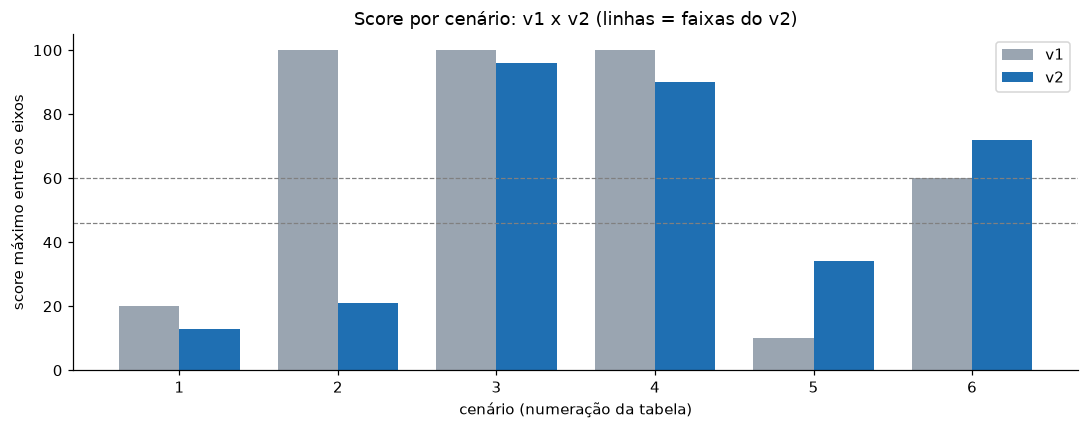

Cenários classificados como o esperado — v1: 3/6 | v2: 5/6


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(comparacao)); w = 0.38
ax.bar(x - w / 2, comparacao[["v1_furto", "v1_incendio"]].max(axis=1), w, label="v1", color="#9aa5b1")
ax.bar(x + w / 2, comparacao[["v2_furto", "v2_incendio"]].max(axis=1), w, label="v2", color="#1f6fb2")
ax.axhline(FAIXA_MEDIO_V2, ls="--", lw=0.8, color="gray"); ax.axhline(FAIXA_ALTO_V2, ls="--", lw=0.8, color="gray")
ax.set_xticks(x, [n.split(".")[0] for n in comparacao.cenario]); ax.set_xlabel("cenário (numeração da tabela)")
ax.set_ylabel("score máximo entre os eixos"); ax.set_ylim(0, 105); ax.legend()
ax.set_title("Score por cenário: v1 x v2 (linhas = faixas do v2)")
plt.tight_layout(); plt.show()
print(f"Cenários classificados como o esperado — v1: {comparacao.v1_acertou.sum()}/{len(comparacao)} | v2: {comparacao.v2_acertou.sum()}/{len(comparacao)}")

## 8. Relatório final consolidado

Visão do **portfólio** (como a seguradora enxergaria a carteira): quantas máquinas em cada nível, quais fazendas concentram risco e quais fatores mais contribuem.

In [14]:
resumo_fazenda = (tabela.groupby("fazenda")
    .agg(maquinas=("maquina", "count"), score_medio_furto=("v2_furto", "mean"), score_medio_incendio=("v2_incendio", "mean"),
         alto=("nivel_v2", lambda s: (s == "ALTO").sum()), medio=("nivel_v2", lambda s: (s == "MEDIO").sum()),
         baixo=("nivel_v2", lambda s: (s == "BAIXO").sum()))
    .round(1))
resumo_fazenda

,maquinas,score_medio_furto,score_medio_incendio,alto,medio,baixo
fazenda,,,,,,
Boa Esperanca,40,33.4,42.2,19,3,18
Santa Rita,40,45.8,37.4,18,6,16
Vale Verde,40,30.1,35.6,12,11,17


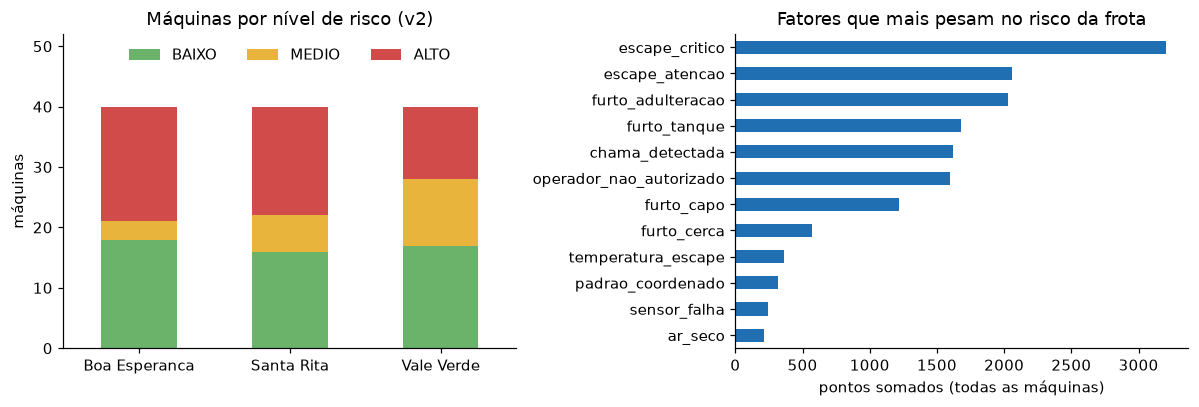

Principais fatores: escape critico (3208 pts); escape atencao (2055 pts); furto adulteracao (2029 pts)


In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
cores = {"BAIXO": "#6bb36b", "MEDIO": "#e8b43c", "ALTO": "#d24b4b"}
contagem = tabela.groupby(["fazenda", "nivel_v2"]).size().unstack(fill_value=0).reindex(columns=NIVEIS, fill_value=0)
contagem.plot(kind="bar", stacked=True, ax=eixos[0], color=[cores[n] for n in NIVEIS], rot=0)
eixos[0].set_title("Máquinas por nível de risco (v2)"); eixos[0].set_xlabel(""); eixos[0].set_ylabel("máquinas")
eixos[0].set_ylim(0, 52); eixos[0].legend(ncol=3, loc="upper center", frameon=False, title=None)

# Fatores: quanto cada tipo de evento contribui para o score total da frota
contrib = {}
por_maq = {m: g.to_dict("records") for m, g in eventos.groupby("maquina")}
for m, lst in por_maq.items():
    med = medidas.loc[medidas.maquina == m].iloc[0]
    r = score_v2(lst, med.temp_escape_max, med.umidade_min)
    for eixo in r["componentes"]:
        for k, v in r["componentes"][eixo].items():
            contrib[k] = contrib.get(k, 0) + v
contrib = pd.Series(contrib).sort_values()
contrib.plot(kind="barh", ax=eixos[1], color="#1f6fb2")
eixos[1].set_title("Fatores que mais pesam no risco da frota"); eixos[1].set_xlabel("pontos somados (todas as máquinas)")
plt.tight_layout(); plt.show()
principais = contrib.sort_values(ascending=False).head(3)
print("Principais fatores:", "; ".join(f"{k.replace('_', ' ')} ({v:.0f} pts)" for k, v in principais.items()))

In [16]:
# Máquinas que o v1 classificava errado e o v2 corrige (e o contrário)
corrigidas = tabela[(tabela.nivel_v1 != tabela.gabarito) & (tabela.nivel_v2 == tabela.gabarito)]
pioradas = tabela[(tabela.nivel_v1 == tabela.gabarito) & (tabela.nivel_v2 != tabela.gabarito)]
acc1 = (tabela.nivel_v1 == tabela.gabarito).mean(); acc2 = (tabela.nivel_v2 == tabela.gabarito).mean()
qualidade = rel_ev["recebidos"] - rel_ev["finais"]

print("RESUMO EXECUTIVO")
print("-" * 60)
print(f"Máquinas analisadas ................ {len(tabela)} em {tabela.fazenda.nunique()} fazendas, 30 dias")
print(f"Eventos recebidos / aproveitados ... {rel_ev['recebidos']} / {rel_ev['finais']} ({qualidade} descartados na limpeza)")
print(f"Medidas de sensor sem leitura ...... {int(tabela.sem_leitura.sum())} máquinas (marcadas, não inventadas)")
print(f"Distribuição (v2) .................. " + ", ".join(f"{n}: {(tabela.nivel_v2 == n).sum()}" for n in NIVEIS))
print(f"Acerto no TESTE v1 -> v2 ({len(teste)} máq.)  {acuracia(teste, 'v1_max', 34, 67):.0%} -> {acuracia(teste, 'v2_max', tm2, ta2):.0%}   (todas as {len(tabela)}: {acc1:.0%} -> {acc2:.0%})")
print(f"Classificações que o v2 corrigiu ... {len(corrigidas)} | que piorou: {len(pioradas)}")
print(f"Cenários de teste como esperado .... v1 {comparacao.v1_acertou.sum()}/{len(comparacao)} -> v2 {comparacao.v2_acertou.sum()}/{len(comparacao)}")
print(f"Testes de validação ................ {(res.resultado == 'PASSOU').sum()}/{len(res)} aprovados")
top = tabela.sort_values("v2_max", ascending=False).head(5)[["maquina", "fazenda", "v2_furto", "v2_incendio", "nivel_v2"]]
print("\nTop 5 máquinas para vistoria prioritária:")
top.reset_index(drop=True)

RESUMO EXECUTIVO
------------------------------------------------------------
Máquinas analisadas ................ 120 em 3 fazendas, 30 dias
Eventos recebidos / aproveitados ... 990 / 896 (94 descartados na limpeza)
Medidas de sensor sem leitura ...... 6 máquinas (marcadas, não inventadas)
Distribuição (v2) .................. BAIXO: 51, MEDIO: 20, ALTO: 49
Acerto no TESTE v1 -> v2 (40 máq.)  40% -> 70%   (todas as 120: 43% -> 62%)
Classificações que o v2 corrigiu ... 23 | que piorou: 1
Cenários de teste como esperado .... v1 3/6 -> v2 5/6
Testes de validação ................ 18/18 aprovados

Top 5 máquinas para vistoria prioritária:


,maquina,fazenda,v2_furto,v2_incendio,nivel_v2
0,TR-051,Boa Esperanca,0,100,ALTO
1,TR-091,Santa Rita,100,99,ALTO
2,TR-090,Boa Esperanca,13,100,ALTO
3,TR-110,Vale Verde,100,24,ALTO
4,TR-118,Santa Rita,100,99,ALTO


### Insights

- **O volume de eventos engana; a combinação e o contexto informam.** O v1 tratava 12 aberturas de capô de rotina como risco máximo (score 100). Com retorno decrescente, peso do horário e padrão coordenado, o v2 coloca esse caso em BAIXO e mantém ALTO para furto noturno coordenado e para incêndio com chama.
- **Incêndio ganha um sinal antes da chama.** Temperatura do escape e ar seco entram no score: no cenário 5 (escape a 52 °C, ar a 22%), o score sobe de 10 (v1) para 34 (v2). Ainda não atravessa a faixa de MÉDIO, então a janela de vistoria preventiva só abre com um evento de atenção a mais ou escape mais próximo dos 60 °C. É o ponto fraco que sobrou (veja a seção 10).
- **Dado ruim é tratado, não escondido.** A limpeza descartou eventos duplicados, tipos inválidos e horas impossíveis, e as leituras de sensor fora de faixa viram "sem leitura" com aviso no alerta. Isso evita tanto um falso ALTO causado por lixo quanto um falso BAIXO por ausência de dado.
- **Uso pela seguradora:** a lista de prioridade (top 5 acima) e o resumo por fazenda apoiam a decisão de onde vistoriar primeiro e como segmentar o prêmio.

## 9. Demonstração prática

A função `executar_demo` roda o fluxo inteiro para uma máquina escolhida, do dado bruto ao alerta. Troque o código da máquina e execute para demonstrar ao vivo.

In [17]:
def executar_demo(maquina):
    ev_m = eventos[eventos.maquina == maquina]
    print(f"Eventos válidos no período: {len(ev_m)}")
    print(ev_m.groupby("tipo").size().rename("ocorrências").to_frame().T.to_string(), end="\n\n")
    print(alerta(maquina, tabela, eventos, medidas))

executar_demo(tabela.sort_values("v2_max", ascending=False).maquina.iloc[1])

Eventos válidos no período: 38
tipo         chama_detectada  escape_atencao  escape_critico  furto_adulteracao  furto_capo  furto_cerca  furto_tanque  operador_nao_autorizado
ocorrências                3              11               3                  2           6            2             7                        4

MAQUINA TR-091 (Santa Rita)  |  nivel geral: ALTO
  [ALTO ] FURTO    score 100/100  | fatores: operador nao autorizado (120.1 pts), furto cerca (91 pts), furto tanque (79 pts)
           acao: Acionar vigilância e conferir a localização da máquina agora; avaliar bloqueio de partida.
  [ALTO ] INCENDIO score  99/100  | fatores: chama detectada (138.6 pts), escape critico (87.6 pts), escape atencao (48.6 pts)
           acao: Inspeção presencial imediata do sistema de escape e da fiação; manter extintor acessível.


## 10. Conclusões, limitações e próximos passos

**O que foi entregue na Sprint 4:** limpeza e validação de dados, modelo de risco refinado (v2) com componentes auditáveis, faixas calibradas com separação treino/teste, bateria de testes com casos extremos, alertas em linguagem clara, comparação entre cenários e relatório consolidado do portfólio.

**Limitações assumidas:**
- Os dados são simulados; a acurácia mede coerência com o gerador, não desempenho em campo. A unidade real só ficou ativa na demonstração do NEXT.
- Pesos e limiares (`DECAIMENTO`, `PESO_NOITE`, 40/60 °C etc.) são ponto de partida informado pela conversa com o ex-gestor de sinistros, não valores estimados de dados reais.
- O gabarito simplifica o risco em três níveis; sinistros reais têm mais nuances (tipo de cultura, época de colheita, valor da máquina).
- O ganho do v2 depende da premissa de que parte das máquinas gera muitos eventos banais de dia (manutenção e abastecimento). Se isso não ocorrer na frota real, a vantagem sobre o v1 diminui.
- No cenário 5 (escape quente e ar seco, sem evento crítico) o v2 não chega a MÉDIO. Próximo passo natural: uma faixa de **pré-alerta** só para as medidas contínuas de temperatura e umidade.

**Próximos passos:** recalibrar pesos e faixas com o histórico real de sinistros da seguradora; validar a hipótese do horário noturno com boletins de ocorrência; levar o v2 para o módulo de scores do painel, mantendo o v1 como referência de comparação.